In [15]:
!pip install blitz-bayesian-pytorch

In [16]:
import warnings
warnings.filterwarnings('ignore')

In [17]:
import matplotlib.pyplot as plt
import math
import pickle
import numpy as np
import torch
import torch.nn as nn
import pandas as pd
import seaborn as sns
import torch.optim as optim
import torch.nn.functional as F
import torch.nn as nn
import json
from blitz.modules import BayesianLinear
from blitz.utils import variational_estimator
from torch.utils.data import TensorDataset, DataLoader
from matplotlib.pyplot import scatter, figure
from scipy import stats
from numpy.ma.core import outer
from sys import stderr

In [18]:
start = -7
end = 7
n = 300
batch_size = 16


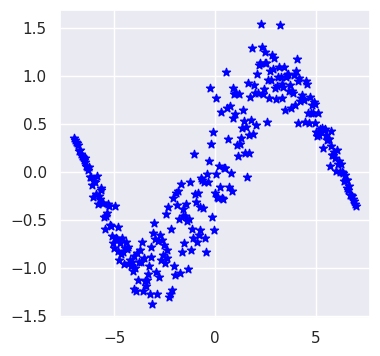

In [19]:
def sample_dataset(start, end, n):
    np.random.seed(0)
    x = np.linspace(start, end, n)
    sample_mean = [math.sin(i/2) for i in x]

    sample_var = [abs((abs(start)+abs(end))/2 - abs(i))/16 for i in x]
    y = stats.norm(sample_mean, sample_var).rvs(random_state=0)
    return x, y

x_train, y_train = sample_dataset(start, end, n)
scatter(x_train, y_train, c="blue", marker="*")

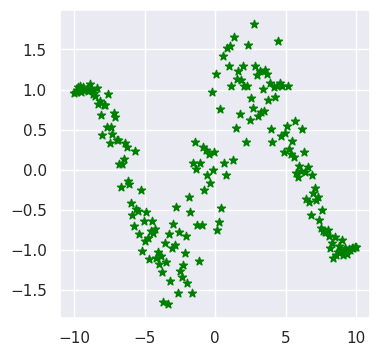

In [20]:
figure(figsize=(4, 4))
# Not exactely the same distribution, but works for now
x_test, y_test = sample_dataset(-10, 10, 200)
scatter(x_test, y_test, c="green", marker="*")

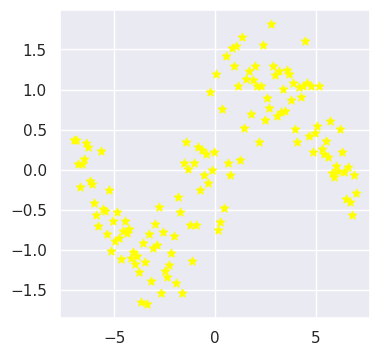

In [21]:
#Plotting In Training Distribution Data Points in the Test Set
# Filter the data to retain only the desired ranges
mask =  (x_test >= -7) &  (x_test <= 7) # Select the ranges -10 to -7 and 7 to 10
x_test_idd = x_test[mask]
y_test_idd = y_test[mask]

plt.figure(figsize=(4, 4))
plt.scatter(x_test_idd, y_test_idd, c="yellow", marker="*")

plt.show()


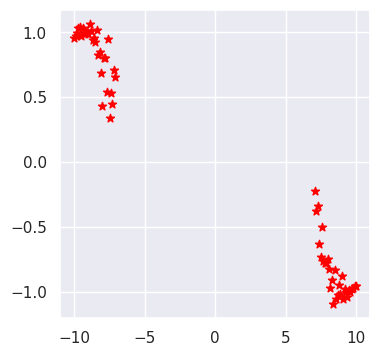

In [22]:
#Plotting Out of Training Distribution Data Points in the Test Set
# Filter the data to retain only the desired ranges
mask = (x_test >= -10) & (x_test < -7) | (x_test > 7) & (x_test <= 10) # Select the ranges -10 to -7 and 7 to 10
x_test_oodd = x_test[mask]
y_test_oodd = y_test[mask]

plt.figure(figsize=(4, 4))
plt.scatter(x_test_oodd, y_test_oodd, c="red", marker="*")

plt.show()


In [23]:

# Train
tensor_x = torch.Tensor(x_train).unsqueeze(1)
tensor_y = torch.Tensor(y_train).unsqueeze(1)
train_dataset = TensorDataset(tensor_x, tensor_y)
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)

#Test for OODD (Out of Data Distribution)
tensor_x_test_oodd = torch.Tensor(x_test_oodd).unsqueeze(1)
tensor_y_test_oodd = torch.Tensor(y_test_oodd).unsqueeze(1)
test_dataset_oodd = TensorDataset(tensor_x_test_oodd, tensor_y_test_oodd)
test_loader_oodd = DataLoader(test_dataset_oodd, batch_size=batch_size, shuffle=True)

#Test for IDD (In Data Distribution)
tensor_x_test_idd = torch.Tensor(x_test_idd).unsqueeze(1)
tensor_y_test_idd = torch.Tensor(y_test_idd).unsqueeze(1)
test_dataset_idd = TensorDataset(tensor_x_test_idd, tensor_y_test_idd)
test_loader_idd = DataLoader(test_dataset_idd, batch_size=batch_size, shuffle=True)

# Test
tensor_x_test = torch.Tensor(x_test).unsqueeze(1)
tensor_y_test = torch.Tensor(y_test).unsqueeze(1)
test_dataset = TensorDataset(tensor_x_test, tensor_y_test)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=True)

In [24]:
class MCDO(nn.Module):
    def __init__(self):
        super(MCDO, self).__init__()
        hidden_size = 61

        # We only have 1 input feature
        self.fc1 = nn.Linear(1, hidden_size)
        self.fc2 = nn.Linear(hidden_size, hidden_size)
        self.out = nn.Linear(hidden_size, 1)
        self.dropout = nn.Dropout(p=0.1)

    def forward(self, x):
        h = self.dropout(torch.relu(self.fc1(x)))
        h = self.dropout(torch.relu(self.fc2(h)))
        out = self.out(h)
        return out

In [25]:

def plot_with_confidence_interval(model, tensor_x_test, tensor_y_test, x_test,y_test,color,start, end):
    samples = 50
    preds = [model(tensor_x_test) for i in range(samples)]
    preds = torch.stack(preds)
    means = preds.mean(axis=0).detach().numpy()
    stds =  preds.std(axis=0).detach().numpy()
    mu = means
    sigma = stds
    # Calculate the 95% confidence interval
    lower_bound = mu - 2 * sigma
    upper_bound = mu + 2 * sigma

    # Count the data points within the confidence interval
    count_within_ci = np.sum((tensor_y_test.numpy() >= lower_bound) & (tensor_y_test.numpy() <= upper_bound))
    percentage_count_within_ci = (count_within_ci / tensor_y_test.shape[0]) * 100
    print(f'Number of data points within the 95% confidence interval: {count_within_ci}')
    print(f'Percentage of data points within the 95% confidence interval: {percentage_count_within_ci}')

    # ~ 95% conf. interval (see https://en.wikipedia.org/wiki/1.96)
    y_vals = [mu, mu + 2 * sigma, mu - 2 * sigma]
    dfs = []

    # Create DF from predictions
    for i in range(3):
        data = {
            "x": list(tensor_x_test.squeeze().numpy()),
            "y": list(y_vals[i].squeeze())
        }
        temp = pd.DataFrame.from_dict(data)
        dfs.append(temp)
    df = pd.concat(dfs).reset_index()

    # Plot predictions with confidence
    sns.set(rc={'figure.figsize': (4, 4)})
    sns_plot = sns.lineplot(data=df, x="x", y="y",color='darkblue')

    # Highlight training range
    plt.axvline(x=start)
    plt.axvline(x=end)

    # Plot test data on top
    scatter(x_test, y_test, color=color, marker="*", alpha=1.0)
    plt.show()
    return percentage_count_within_ci


In [26]:
def train_and_evaluate_net(net, train_loader, test_loader, tensor_x_test, tensor_y_test,  x_test, y_test, color, test_dataset,num_epochs=150, learning_rate=0.001):
    # Define loss and optimizer
    device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
    criterion = torch.nn.MSELoss()
    optimizer = optim.Adam(net.parameters(), lr=learning_rate)
    net.train()
    net.to(device)

    for epoch in range(num_epochs):
        # Train loop
        for batch in train_loader:
            x, y = batch[0].to(device), batch[1].to(device)
            optimizer.zero_grad()
            out = net(x)
            loss = criterion(y, out)
            loss.backward()
            optimizer.step()
        if epoch % 10 == 0:
            all_test_losses = []
            # Test loop
            for batch in test_loader:
                x, y = batch[0].to(device), batch[1].to(device)
                # Sample MC Dropout predictions
                outs = []
                for i in range(10):
                  net.train()
                  out = net(x)
                  outs.append(out)

                # Take mean prediction
                out = sum(outs)/len(outs)
                all_test_losses.append(loss.item())
            test_loss = sum(all_test_losses) / len(all_test_losses)

    percentage_count_within_ci=plot_with_confidence_interval(net, tensor_x_test, tensor_y_test,x_test,y_test,color,start, end)
    return loss, test_loss,net,percentage_count_within_ci

def Neural_Network(net,train_loader,test_loader,tensor_x_test,tensor_y_test, x_test,y_test,color,tst_dtast):
    train_loss, test_loss,net,percentage_count_within_ci = train_and_evaluate_net(net, train_loader, test_loader,tensor_x_test,tensor_y_test, x_test,y_test,color,tst_dtast)
    return train_loss, test_loss,net,percentage_count_within_ci



In [27]:

# Example JSON string
json_str = '''
{
  "test_loaders": ["test_loader", "test_loader_oodd", "test_loader_idd"],
  "test_tensors_x":["tensor_x_test","tensor_x_test_oodd","tensor_x_test_idd"],
  "test_tensors_y":["tensor_y_test","tensor_y_test_oodd","tensor_y_test_idd"],
  "test_datasets":["test_dataset","test_dataset_oodd","test_dataset_idd"],
  "color":["green","red","yellow"],
  "testset_x":["x_test","x_test_oodd","x_test_idd"],
  "testset_y":["y_test","y_test_oodd","y_test_idd"],
  "output_dirs": ["pickled_models_", "pickled_models_oodd_", "pickled_models_idd_"],
  "error_metrics":["em","em_oodd","em_idd"]
}
'''

# Parse JSON
data = json.loads(json_str)

# Map string names to actual variables
test_loader_vars = {
    "test_loader": test_loader,
    "test_loader_oodd": test_loader_oodd,
    "test_loader_idd": test_loader_idd
}
tensor_x_mapping = {
    "tensor_x_test": tensor_x_test,
    "tensor_x_test_oodd": tensor_x_test_oodd,
    "tensor_x_test_idd": tensor_x_test_idd
}

tensor_y_mapping = {
    "tensor_y_test": tensor_y_test,
    "tensor_y_test_oodd": tensor_y_test_oodd,
    "tensor_y_test_idd": tensor_y_test_idd
}
testset_x_mapping = {
    "x_test": x_test,
    "x_test_oodd": x_test_oodd,
    "x_test_idd": x_test_idd
}

# Mapping from string names to actual variables for testset_y
testset_y_mapping = {
    "y_test": y_test,
    "y_test_oodd": y_test_oodd,
    "y_test_idd": y_test_idd
}
test_datasets_mapping = {
    "test_dataset": test_dataset,
    "test_dataset_oodd": test_dataset_oodd,
    "test_dataset_idd": test_dataset_idd
}
# Access corresponding values using a loop
test_loaders = data["test_loaders"]
test_tensors_x=data["test_tensors_x"]
test_tensors_y=data["test_tensors_y"]
test_datasets=data["test_datasets"]
color=data["color"]
testset_x=data["testset_x"]
testset_y=data["testset_y"]
output_dirs = data["output_dirs"]
error_mets=data["error_metrics"]



Number of data points within the 95% confidence interval: 113
Percentage of data points within the 95% confidence interval: 56.49999999999999


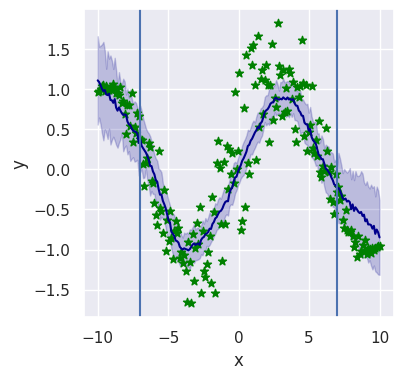

Number of data points within the 95% confidence interval: 116
Percentage of data points within the 95% confidence interval: 57.99999999999999


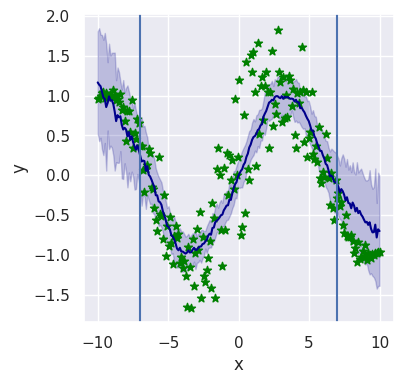

Number of data points within the 95% confidence interval: 105
Percentage of data points within the 95% confidence interval: 52.5


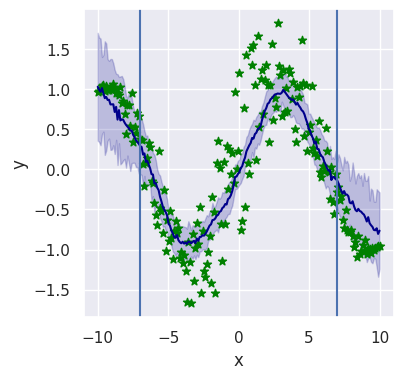

Number of data points within the 95% confidence interval: 113
Percentage of data points within the 95% confidence interval: 56.49999999999999


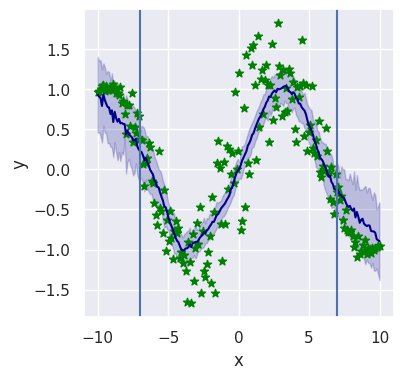

Number of data points within the 95% confidence interval: 94
Percentage of data points within the 95% confidence interval: 47.0


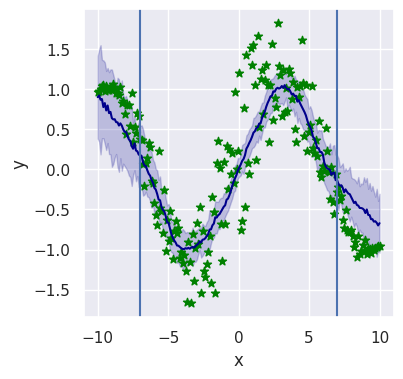

Number of data points within the 95% confidence interval: 97
Percentage of data points within the 95% confidence interval: 48.5


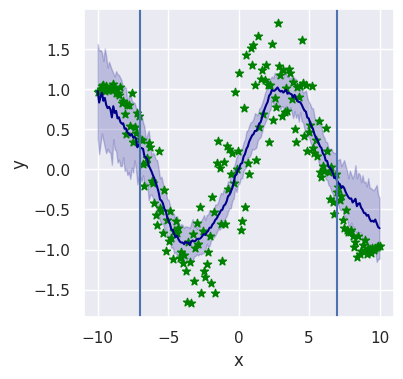

Number of data points within the 95% confidence interval: 100
Percentage of data points within the 95% confidence interval: 50.0


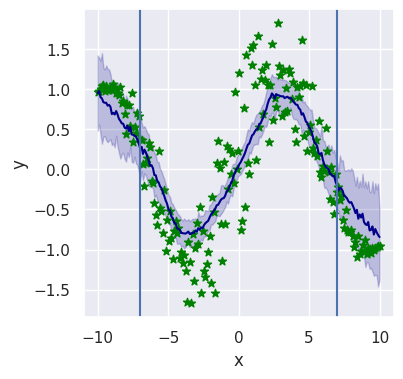

Number of data points within the 95% confidence interval: 111
Percentage of data points within the 95% confidence interval: 55.50000000000001


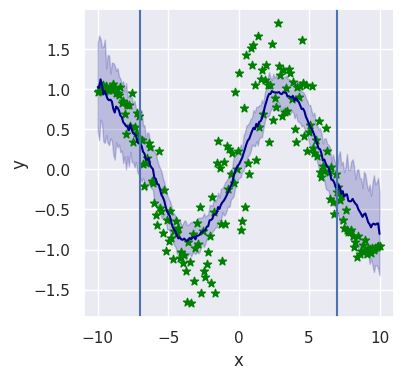

Number of data points within the 95% confidence interval: 110
Percentage of data points within the 95% confidence interval: 55.00000000000001


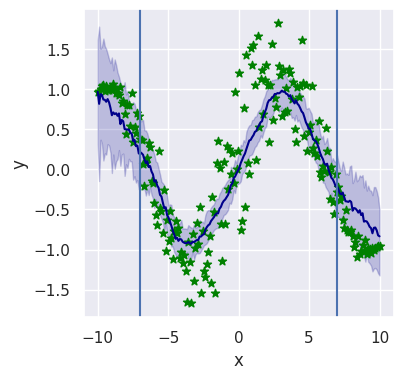

Number of data points within the 95% confidence interval: 93
Percentage of data points within the 95% confidence interval: 46.5


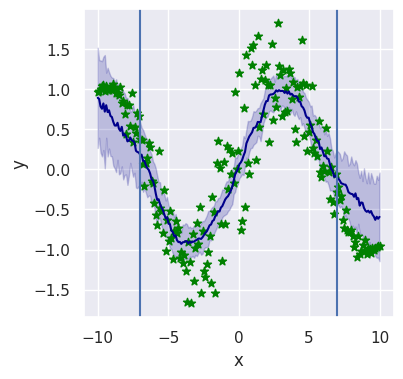

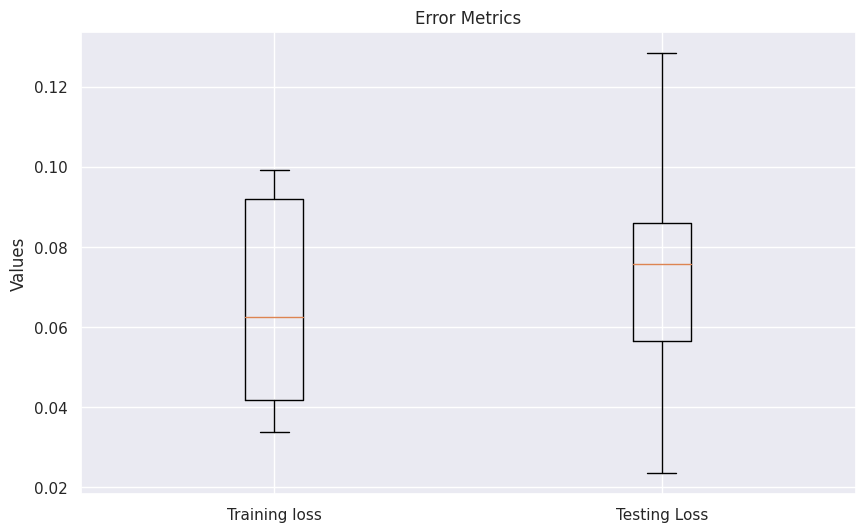

    Training Loss  Testing Loss  % of points in Confidence Interval
1        0.093477      0.052051                                56.5
2        0.096687      0.100988                                58.0
3        0.058748      0.088339                                52.5
4        0.037480      0.023555                                56.5
5        0.044460      0.128536                                47.0
6        0.066129      0.046649                                48.5
7        0.040965      0.069389                                50.0
8        0.033772      0.078866                                55.5
9        0.099167      0.079409                                55.0
10       0.087852      0.072776                                46.5
Mean of Gausiann Training Loss of 10 runs  0.06587374843657016
Standard Deviation of Gausiann Training Loss of 10 runs  0.02503878646675601
Mean of Gausiann Testing Loss of 10 runs  0.07405579090118408
Standard Deviation of Gausiann Testing Loss of 10 

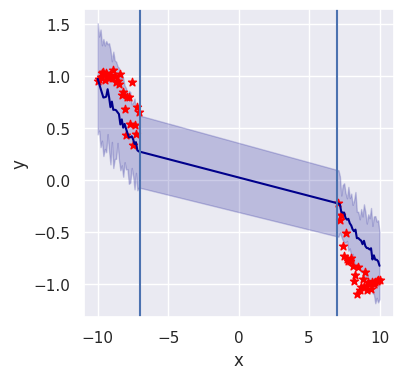

Number of data points within the 95% confidence interval: 38
Percentage of data points within the 95% confidence interval: 63.33333333333333


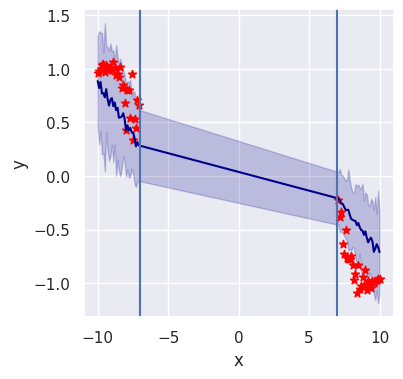

Number of data points within the 95% confidence interval: 49
Percentage of data points within the 95% confidence interval: 81.66666666666667


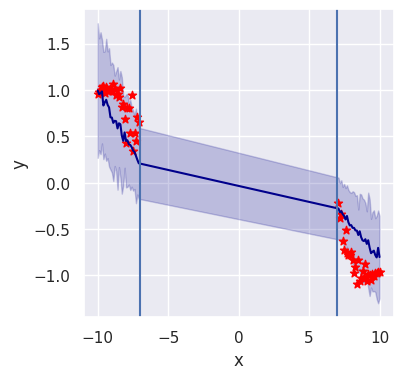

Number of data points within the 95% confidence interval: 55
Percentage of data points within the 95% confidence interval: 91.66666666666666


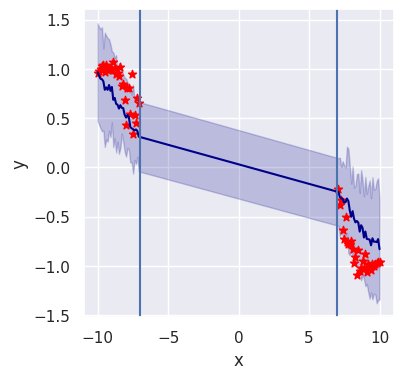

Number of data points within the 95% confidence interval: 43
Percentage of data points within the 95% confidence interval: 71.66666666666667


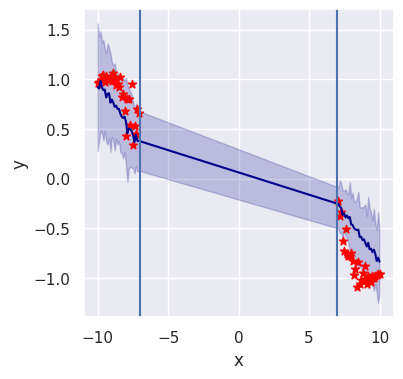

Number of data points within the 95% confidence interval: 57
Percentage of data points within the 95% confidence interval: 95.0


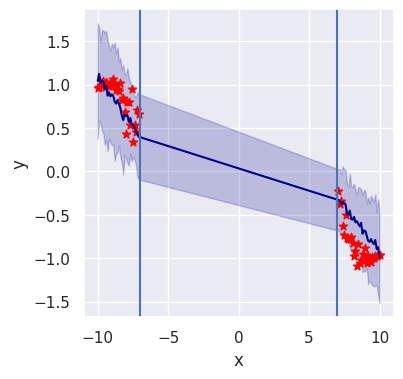

Number of data points within the 95% confidence interval: 39
Percentage of data points within the 95% confidence interval: 65.0


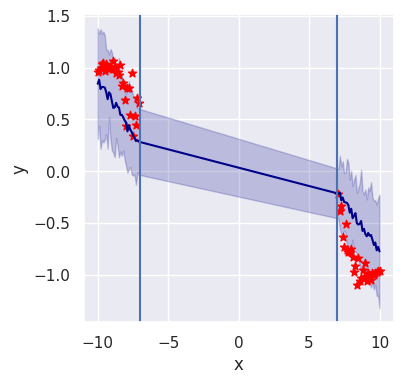

Number of data points within the 95% confidence interval: 51
Percentage of data points within the 95% confidence interval: 85.0


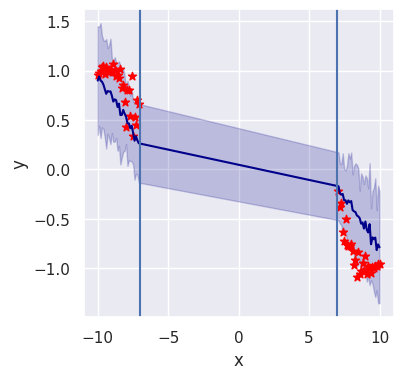

Number of data points within the 95% confidence interval: 40
Percentage of data points within the 95% confidence interval: 66.66666666666666


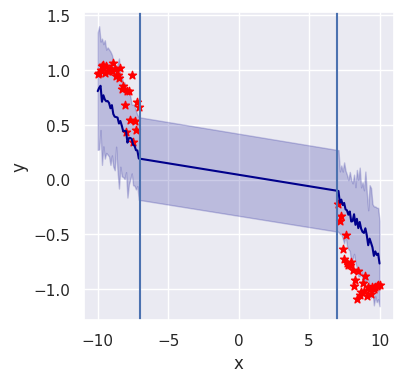

Number of data points within the 95% confidence interval: 41
Percentage of data points within the 95% confidence interval: 68.33333333333333


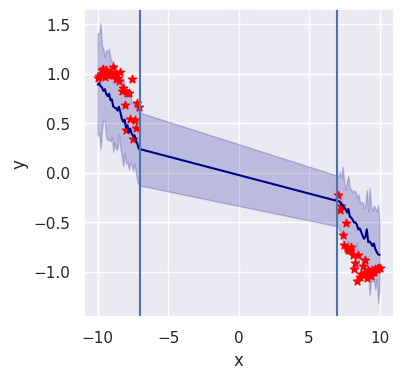

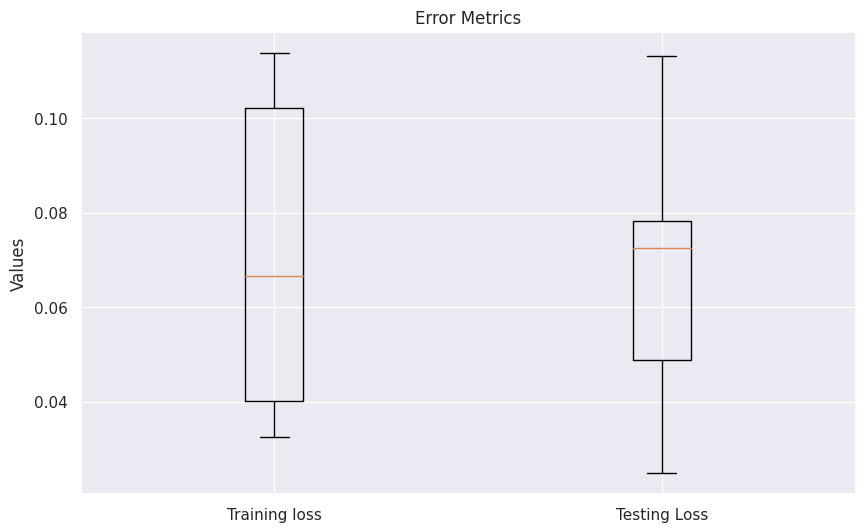

    Training Loss  Testing Loss  % of points in Confidence Interval
1        0.093668      0.078700                           61.666667
2        0.078338      0.024987                           63.333333
3        0.034164      0.074040                           81.666667
4        0.106698      0.090711                           91.666667
5        0.032487      0.049747                           71.666667
6        0.113894      0.044665                           95.000000
7        0.105066      0.077017                           65.000000
8        0.039345      0.113174                           85.000000
9        0.055100      0.071145                           66.666667
10       0.042751      0.048693                           68.333333
Mean of Gausiann Training Loss of 10 runs  0.07015112191438674
Standard Deviation of Gausiann Training Loss of 10 runs  0.03119000327975089
Mean of Gausiann Testing Loss of 10 runs  0.06728795897215605
Standard Deviation of Gausiann Testing Loss of 10 

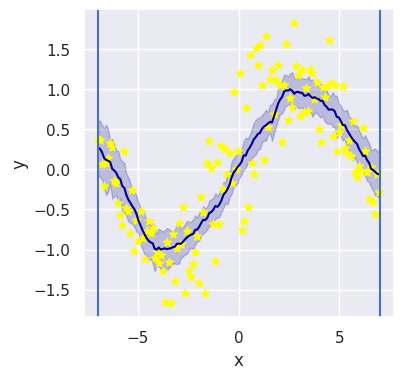

Number of data points within the 95% confidence interval: 56
Percentage of data points within the 95% confidence interval: 40.0


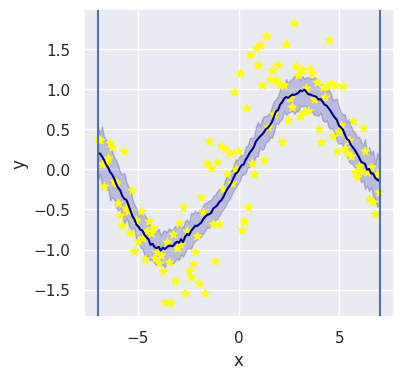

Number of data points within the 95% confidence interval: 52
Percentage of data points within the 95% confidence interval: 37.142857142857146


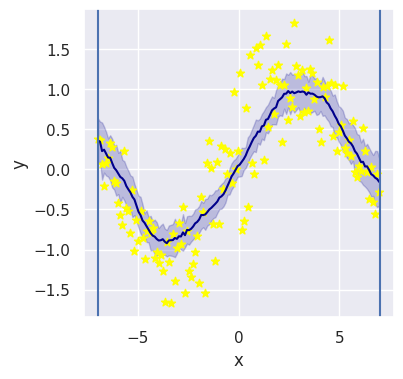

Number of data points within the 95% confidence interval: 54
Percentage of data points within the 95% confidence interval: 38.57142857142858


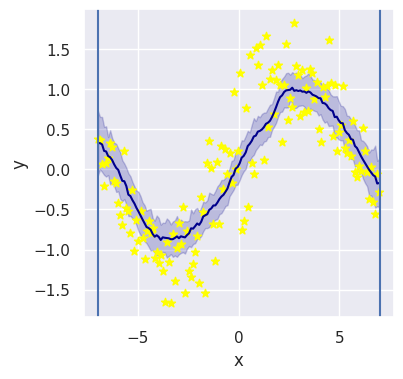

Number of data points within the 95% confidence interval: 54
Percentage of data points within the 95% confidence interval: 38.57142857142858


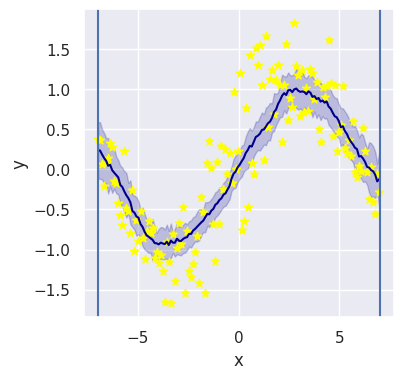

Number of data points within the 95% confidence interval: 58
Percentage of data points within the 95% confidence interval: 41.42857142857143


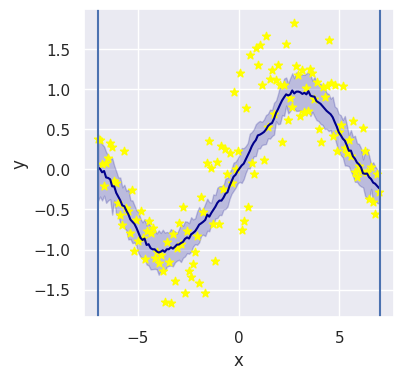

Number of data points within the 95% confidence interval: 52
Percentage of data points within the 95% confidence interval: 37.142857142857146


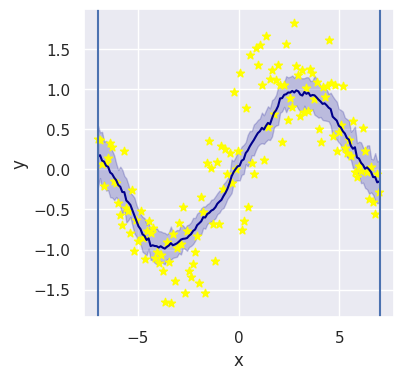

Number of data points within the 95% confidence interval: 57
Percentage of data points within the 95% confidence interval: 40.714285714285715


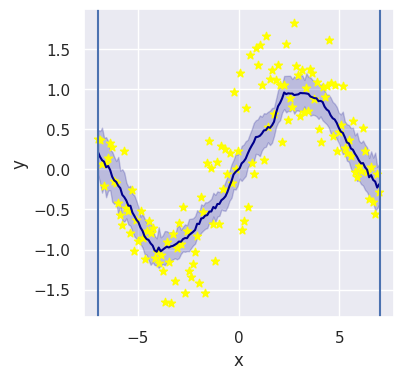

Number of data points within the 95% confidence interval: 56
Percentage of data points within the 95% confidence interval: 40.0


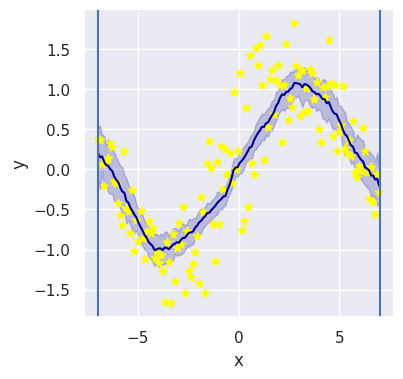

Number of data points within the 95% confidence interval: 53
Percentage of data points within the 95% confidence interval: 37.857142857142854


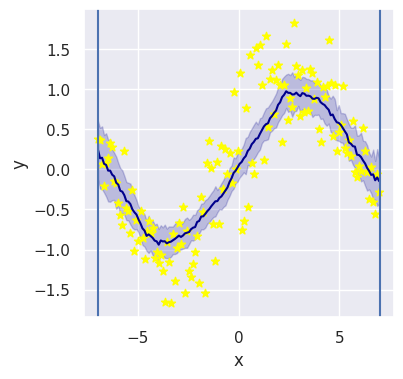

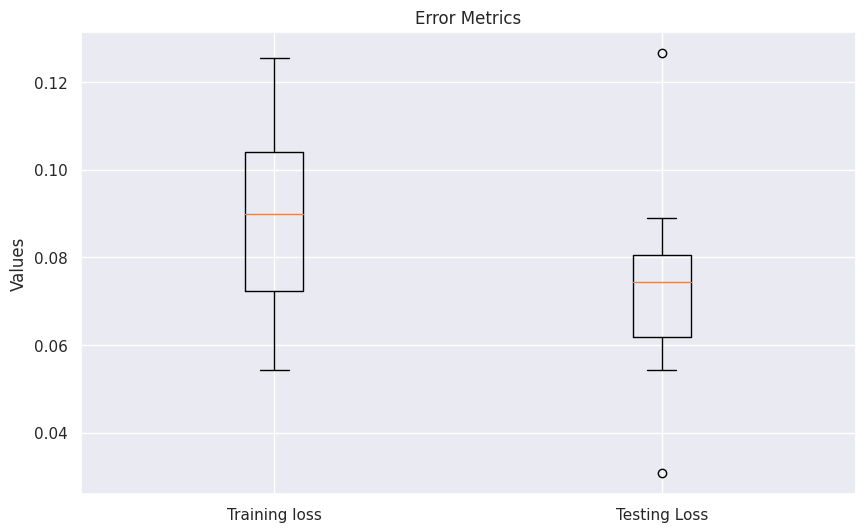

    Training Loss  Testing Loss  % of points in Confidence Interval
1        0.095142      0.080658                           41.428571
2        0.054372      0.080375                           40.000000
3        0.125419      0.088994                           37.142857
4        0.114341      0.126661                           38.571429
5        0.060407      0.054366                           38.571429
6        0.092375      0.080047                           41.428571
7        0.068501      0.060688                           37.142857
8        0.087246      0.068902                           40.714286
9        0.084249      0.030894                           40.000000
10       0.107155      0.065675                           37.857143
Mean of Gausiann Training Loss of 10 runs  0.0889207236468792
Standard Deviation of Gausiann Training Loss of 10 runs  0.02193090826276733
Mean of Gausiann Testing Loss of 10 runs  0.07372610177844763
Standard Deviation of Gausiann Testing Loss of 10 r

In [ ]:
for tst_loader,tnsor_x_test,tnsor_y_test, col, x_test,y_test,output_dir, error_metric,tst_dtast in zip(test_loaders,test_tensors_x,test_tensors_y,color,testset_x,testset_y,output_dirs,error_mets,test_datasets):
  train_losses=[]
  test_losses=[]
  percentages_count_within_ci=[]
  for i in range(10):
    net=MCDO()
    tr_loss,test_loss,model,percentage_count_within_ci = Neural_Network(net,train_loader,test_loader_vars[tst_loader],tensor_x_mapping[tnsor_x_test],tensor_y_mapping[tnsor_y_test],testset_x_mapping[x_test],testset_y_mapping[y_test],col,test_datasets_mapping[tst_dtast])
    error_metrics=tr_loss,test_loss,model,percentage_count_within_ci
    model_filename = f"{output_dir}model_{i}.pkl"
    with open(model_filename, 'wb') as file:
      pickle.dump(error_metrics, file)
    train_losses.append(tr_loss)
    test_losses.append(test_loss)

    percentages_count_within_ci.append(percentage_count_within_ci)
  # Extract numerical values from the tensors and remove grad_fn
  tr_loss_values= [tensor.item() for tensor in train_losses]
  test_loss_values=test_losses

  # Create a figure and axis
  fig, ax = plt.subplots(figsize=(10, 6))
  # Create box plots for each dataset
  box_plot_data = [tr_loss_values, test_loss_values]
  box_labels = ['Training loss', 'Testing Loss']
  ax.boxplot(box_plot_data, labels=box_labels)
  # Add labels and title
  ax.set_ylabel('Values')
  ax.set_title('Error Metrics')
  plt.savefig(f'mcdonn_arch_{error_metric}.png', dpi=300)
  # Show the plot
  plt.show()

  mean_gaus_train_loss = np.mean(tr_loss_values)
  std_dev_gaus_train_loss = np.std(tr_loss_values)

  mean_gaus_test_loss = np.mean(test_loss_values)
  std_dev_gaus_test_loss = np.std(test_loss_values)

  mean_percentages_count_within_ci = np.mean(percentages_count_within_ci)
  std_dev_percentages_count_within_ci = np.std(percentages_count_within_ci)

  # Create a DataFrame from the lists
  data = {
    'Training Loss': tr_loss_values,
    'Testing Loss': test_loss_values,
    '% of points in Confidence Interval':percentages_count_within_ci,
  }

  num_columns = len(data)

  column_names = ['Training Loss','Testing Loss','% of points in Confidence Interval']
  # Create a DataFrame with dynamic column names
  df = pd.DataFrame(data, columns=column_names)
  df.index += 1
  # Display the DataFrame as a table
  print(df)
  df.to_csv(f'mcdonn_results_{error_metric}.txt', index=True)
  print('Mean of Gausiann Training Loss of 10 runs ', mean_gaus_train_loss)
  print('Standard Deviation of Gausiann Training Loss of 10 runs ' , std_dev_gaus_train_loss )

  print('Mean of Gausiann Testing Loss of 10 runs ',mean_gaus_test_loss )
  print('Standard Deviation of Gausiann Testing Loss of 10 runs ',std_dev_gaus_test_loss)

  print('Mean of percentage of 95% conf interval for 10 runs in data',mean_percentages_count_within_ci)
  print('Standard Deviation of percentage of 95% conf interval for 10 runs in data ' , std_dev_percentages_count_within_ci)

  # File path
  file_path = f'mcdonn_summary_{error_metric}.txt'

  # Open the file in write mode
  with open(file_path, 'w') as file:
    # Write the results to the file
    file.write('Mean of Gaussian Training Loss of 10 runs: {}\n'.format(mean_gaus_train_loss))
    file.write('Standard Deviation of Gaussian Training Loss of 10 runs: {}\n\n'.format(std_dev_gaus_train_loss))

    file.write('Mean of Gaussian Testing Loss of 10 runs: {}\n'.format(mean_gaus_test_loss))
    file.write('Standard Deviation of Gaussian Testing Loss of 10 runs: {}\n\n'.format(std_dev_gaus_test_loss))

    file.write('Mean of percentage of 95% conf interval for 10 runs in data {}\n'.format(mean_percentages_count_within_ci))
    file.write('Standard Deviation of percentage of 95% conf interval for 10 runs in data {}\n\n'.format(std_dev_percentages_count_within_ci))

  # Print a message indicating the file has been saved
  print(f'Results summary saved to {file_path}')
